Image shape: (396, 396, 3)


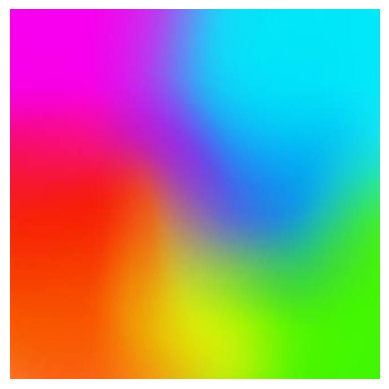

In [10]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

img = Image.open('images.jpeg').convert('RGB')
img = img.resize((396, 396))

img_array = np.array(img)

print("Image shape:", img_array.shape)

plt.imshow(img_array)
plt.axis('off')
plt.show()

In [12]:
X = img_array.reshape(-1, 3)

print("Dataset shape:", X.shape)

Dataset shape: (156816, 3)


In [14]:
kmeans = KMeans(
    n_clusters=8,
    init='k-means++',
    random_state=42,
    n_init=3
)

kmeans.fit(X)

C:\Users\Purnishamahi\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Purnishamahi\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Purnishamahi\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Purnishamahi\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Purnishamahi\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    h

KMeans(n_init=3, random_state=42)

In [16]:
compressed_pixels = kmeans.cluster_centers_[
    kmeans.labels_
]

compressed_image = compressed_pixels.reshape(396, 396, 3)
compressed_image = np.clip(
    compressed_image, 0, 255
).astype(np.uint8)

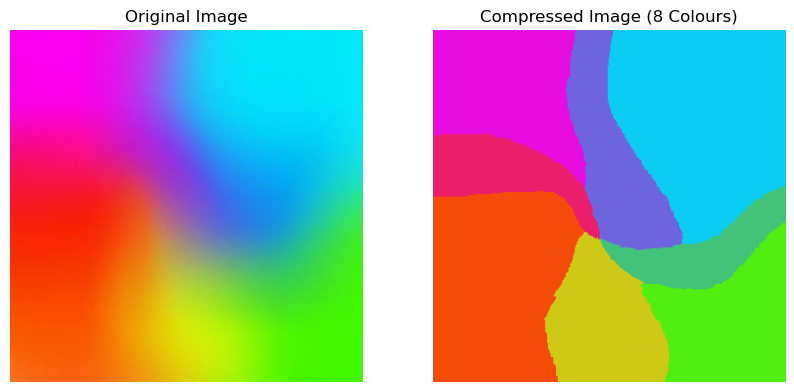

In [18]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_array)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(compressed_image)
plt.title('Compressed Image (8 Colours)')
plt.axis('off')

plt.show()

In [22]:
compressed_img = Image.fromarray(compressed_image)
compressed_img.save('compressed_image.png')

print("Compressed image saved successfully!")

Compressed image saved successfully!
